# Model 03 — Customer Lifetime Value Prediction

## 01. Data Validation & Exploratory Data Analysis

### Objective

This notebook performs the initial validation and exploratory analysis of the
Online Retail II dataset selected for the Customer Lifetime Value Prediction
model.

The analysis will focus on:

- Dataset structure and schema
- Data types and basic statistics
- Missing values
- Duplicate records
- Transaction validity
- Cancelled transactions
- Customer and transaction coverage
- Temporal characteristics
- Revenue-related distributions
- Initial data-quality observations

> **Note:** The final CLV definition, prediction horizon, feature set, and modeling
> strategy will be determined after understanding the dataset and its temporal
> structure. No target definition is assumed at this stage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
# Ensure the Excel reader dependency is available in this notebook's Python environment
import sys
import subprocess

try:
    import openpyxl
except ImportError:
    print("openpyxl is not available. Installing it in the active notebook environment...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-U", "openpyxl"])
    import openpyxl

print(f"openpyxl version: {openpyxl.__version__}")


openpyxl version: 3.1.5


In [3]:
# Model 03 root directory
# Notebook location: ml/model_03_customer_lifetime_value/notebooks/
MODEL_ROOT = Path.cwd().parent

# Raw dataset location
DATA_PATH = MODEL_ROOT / "data" / "raw" / "online_retail_II.xlsx"

print("Model 03 root:")
print(MODEL_ROOT)

print("\nDataset path:")
print(DATA_PATH)

print("\nDataset exists:", DATA_PATH.exists())

Model 03 root:
d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_03_customer_lifetime_value

Dataset path:
d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_03_customer_lifetime_value\data\raw\online_retail_II.xlsx

Dataset exists: True


## 1. Dataset Loading

The selected dataset is the UCI Online Retail II dataset.

Before loading the transaction data, the workbook structure will be inspected
to identify the available sheets.

In [4]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:")
for sheet in excel_file.sheet_names:
    print(f"- {sheet}")

Available sheets:
- Year 2009-2010
- Year 2010-2011


In [5]:
for sheet in excel_file.sheet_names:
    temp = pd.read_excel(excel_file, sheet_name=sheet)

    print(f"\nSheet: {sheet}")
    print(f"Rows   : {temp.shape[0]:,}")
    print(f"Columns: {temp.shape[1]:,}")


Sheet: Year 2009-2010
Rows   : 525,461
Columns: 8

Sheet: Year 2010-2011
Rows   : 541,910
Columns: 8


## 2. Load Transaction Data

The Online Retail II workbook contains transaction records distributed across
its available worksheets.

The worksheets will be loaded and combined into a single transaction-level
DataFrame for subsequent validation and analysis.

No records will be removed or transformed at this stage.

In [6]:
# Load each worksheet
data_frames = {}

for sheet in excel_file.sheet_names:
    data_frames[sheet] = pd.read_excel(
        excel_file,
        sheet_name=sheet
    )

    print(
        f"{sheet}: "
        f"{data_frames[sheet].shape[0]:,} rows × "
        f"{data_frames[sheet].shape[1]} columns"
    )

Year 2009-2010: 525,461 rows × 8 columns
Year 2010-2011: 541,910 rows × 8 columns


In [7]:
# Combine all transaction records
df = pd.concat(
    data_frames.values(),
    ignore_index=True
)

print(f"Combined dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Combined dataset shape: 1,067,371 rows × 8 columns


In [8]:
# Preview the dataset
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 3. Schema Validation

This section validates the structure of the combined transaction dataset.

The following aspects will be examined:

- Column names
- Data types
- Number of records
- Number of unique values
- Initial value representation

The purpose is to understand the raw dataset before applying any cleaning or
feature engineering.

In [9]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [10]:
# Column names and data types
schema = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_values": df.isna().sum().values,
    "missing_percentage": (
        df.isna().mean().mul(100).round(2).values
    ),
    "unique_values": [
        df[column].nunique(dropna=True)
        for column in df.columns
    ]
})

schema

,column,dtype,missing_values,missing_percentage,unique_values
0,Invoice,object,0,0.00,53628
1,StockCode,object,0,0.00,5305
2,Description,object,4382,0.41,5698
3,Quantity,int64,0,0.00,1057
4,InvoiceDate,datetime64[us],0,0.00,47635
5,Price,float64,0,0.00,2807
6,Customer ID,float64,243007,22.77,5942
7,Country,str,0,0.00,43


In [11]:
# Basic descriptive statistics
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,"1,067,371.00","53,628.00","537,434.00","1,350.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,067,371.00",NaN,NaN,NaN,9.94,"-80,995.00",1.00,3.00,10.00,"80,995.00",172.71
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,"1,067,371.00",NaN,NaN,NaN,4.65,"-53,594.36",1.25,2.10,4.15,"38,970.00",123.55
Customer ID,"824,364.00",NaN,NaN,NaN,"15,324.64","12,346.00","13,975.00","15,255.00","16,797.00","18,287.00","1,697.46"
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Missing Values Analysis

Missing values are evaluated before any cleaning or transformation is applied.

The analysis will identify:

- Number of missing values per column
- Percentage of missing values
- Columns significantly affected by missing data
- Whether missingness is concentrated in customer-identifying or transaction-related fields

No records will be removed or imputed at this stage.

In [12]:
# Missing-value summary
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = (
    missing_summary
    .sort_values("missing_count", ascending=False)
)

missing_summary

,missing_count,missing_percentage
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


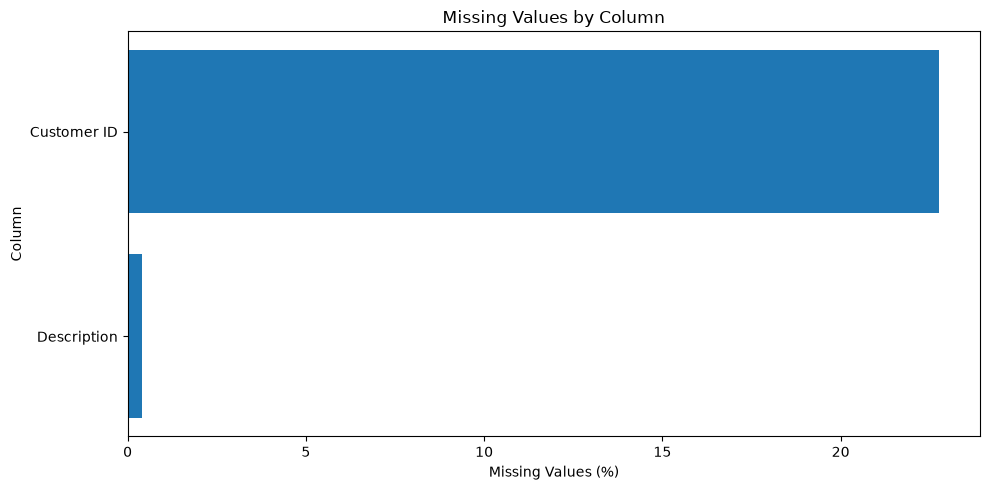

In [13]:
# Visualize missing values
missing_plot = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=True)
)

plt.figure(figsize=(10, 5))

plt.barh(
    missing_plot.index,
    missing_plot["missing_percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.title("Missing Values by Column")

plt.tight_layout()
plt.show()

In [14]:
# Number of complete and incomplete records
complete_rows = df.notna().all(axis=1).sum()
incomplete_rows = df.isna().any(axis=1).sum()

print(f"Complete records  : {complete_rows:,}")
print(f"Incomplete records: {incomplete_rows:,}")
print(f"Total records     : {len(df):,}")

Complete records  : 824,364
Incomplete records: 243,007
Total records     : 1,067,371


## 5. Duplicate Record Analysis

Duplicate records are examined to determine whether identical transaction
records exist in the raw dataset.

Duplicates will be quantified but not removed at this stage.

This distinction is important because repeated-looking transaction records
must be investigated before deciding whether they represent genuine duplicate
records or valid business transactions.

In [15]:
# Exact duplicate analysis
duplicate_count = df.duplicated().sum()

print(f"Exact duplicate records: {duplicate_count:,}")
print(
    f"Duplicate percentage: "
    f"{(duplicate_count / len(df) * 100):.2f}%"
)

Exact duplicate records: 34,335
Duplicate percentage: 3.22%


In [16]:
# Inspect duplicate records, if any exist
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

duplicates.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,"16,329.00",United Kingdom


### Validation Note

The presence of duplicate rows does not automatically mean that they should
be removed.

Any duplicate records identified here will be evaluated together with the
transaction structure and business meaning before the cleaning stage.

## 6. Transaction Validity Analysis

This section examines transaction-level validity before any cleaning is performed.

The Online Retail II dataset uses `Quantity` and `Price` for transaction
quantity and unit price. The notebook keeps the original dataset column names
unchanged and uses detected column variables for analysis.

No records will be removed in this section.


In [17]:
# Detect the transaction columns from the actual Online Retail II schema

invoice_candidates = ["Invoice", "InvoiceNo"]
price_candidates = ["Price", "UnitPrice"]

invoice_column = next(
    (column for column in invoice_candidates if column in df.columns),
    None
)

price_column = next(
    (column for column in price_candidates if column in df.columns),
    None
)

required_columns = ["Quantity"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if invoice_column is None:
    raise KeyError(
        "Invoice column not found. "
        f"Available columns: {df.columns.tolist()}"
    )

if price_column is None:
    raise KeyError(
        "Price column not found. "
        f"Available columns: {df.columns.tolist()}"
    )

if missing_columns:
    raise KeyError(
        f"Required columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

print(f"Invoice column detected : {invoice_column}")
print(f"Price column detected   : {price_column}")
print("Quantity column detected: Quantity")


Invoice column detected : Invoice
Price column detected   : Price
Quantity column detected: Quantity


In [18]:
# Inspect Quantity and Price

print("Quantity Summary")
display(df["Quantity"].describe())

print(f"\n{price_column} Summary")
display(df[price_column].describe())


Quantity Summary


count   1,067,371.00
mean            9.94
std           172.71
min       -80,995.00
25%             1.00
50%             3.00
75%            10.00
max        80,995.00
Name: Quantity, dtype: float64


Price Summary


count   1,067,371.00
mean            4.65
std           123.55
min       -53,594.36
25%             1.25
50%             2.10
75%             4.15
max        38,970.00
Name: Price, dtype: float64

In [19]:
# Quantity validity

quantity_checks = pd.DataFrame(
    {
        "count": [
            int(df["Quantity"].isna().sum()),
            int((df["Quantity"] == 0).sum()),
            int((df["Quantity"] < 0).sum()),
            int((df["Quantity"] > 0).sum()),
        ]
    },
    index=[
        "missing_quantity",
        "zero_quantity",
        "negative_quantity",
        "positive_quantity",
    ],
)

quantity_checks


,count
missing_quantity,0
zero_quantity,0
negative_quantity,22950
positive_quantity,1044421


In [20]:
# Price validity

price_checks = pd.DataFrame(
    {
        "count": [
            int(df[price_column].isna().sum()),
            int((df[price_column] == 0).sum()),
            int((df[price_column] < 0).sum()),
            int((df[price_column] > 0).sum()),
        ]
    },
    index=[
        "missing_price",
        "zero_price",
        "negative_price",
        "positive_price",
    ],
)

price_checks


,count
missing_price,0
zero_price,6202
negative_price,5
positive_price,1061164


## 7. Cancelled Transaction Analysis

Online Retail II identifies cancelled invoices using an invoice number
beginning with `C`.

Cancelled transactions are analysed separately because they represent a
different transaction state from completed purchases.

They will not be removed at this stage.


In [21]:
# Identify cancelled invoices

invoice_as_string = df[invoice_column].astype("string")

cancelled_mask = invoice_as_string.str.startswith(
    "C",
    na=False,
)

cancelled_count = int(cancelled_mask.sum())
non_cancelled_count = int((~cancelled_mask).sum())

print(f"Cancelled records    : {cancelled_count:,}")
print(f"Non-cancelled records: {non_cancelled_count:,}")
print(
    f"Cancelled percentage : "
    f"{cancelled_count / len(df) * 100:.2f}%"
)


Cancelled records    : 19,494
Non-cancelled records: 1,047,877
Cancelled percentage : 1.83%


In [22]:
# Compare cancelled and non-cancelled transactions

cancellation_summary = pd.DataFrame(
    {
        "record_count": [
            cancelled_count,
            non_cancelled_count,
        ],
        "mean_quantity": [
            df.loc[cancelled_mask, "Quantity"].mean(),
            df.loc[~cancelled_mask, "Quantity"].mean(),
        ],
        "mean_price": [
            df.loc[cancelled_mask, price_column].mean(),
            df.loc[~cancelled_mask, price_column].mean(),
        ],
    },
    index=["Cancelled", "Non-cancelled"],
)

cancellation_summary


,record_count,mean_quantity,mean_price
Cancelled,19494,-25.19,44.87
Non-cancelled,1047877,10.59,3.90


## 8. Transaction Revenue Sanity Check

A raw transaction-level monetary value is calculated as:

`TransactionRevenue = Quantity × Price`

This is an exploratory monetary measure only.

It is not the final CLV target. The final target will be defined later after
the temporal structure, observation period, prediction horizon, cancellations,
and customer-level aggregation strategy have been established.


In [23]:
# Calculate raw transaction-level revenue

df["TransactionRevenue"] = (
    df["Quantity"] * df[price_column]
)

df["TransactionRevenue"].describe()


count   1,067,371.00
mean           18.07
std           292.42
min      -168,469.60
25%             3.75
50%             9.90
75%            17.70
max       168,469.60
Name: TransactionRevenue, dtype: float64

In [24]:
# Inspect highest raw transaction values

(
    df[
        [
            invoice_column,
            "Quantity",
            price_column,
            "TransactionRevenue",
        ]
    ]
    .sort_values("TransactionRevenue", ascending=False)
    .head(20)
)


,Invoice,Quantity,Price,TransactionRevenue
1065882,581483,80995,2.08,"168,469.60"
587080,541431,74215,1.04,"77,183.60"
748132,556444,60,649.50,"38,970.00"
241827,512771,1,"25,111.09","25,111.09"
432176,530715,9360,1.69,"15,818.40"
517955,537632,1,"13,541.33","13,541.33"
540478,537632,1,"13,541.33","13,541.33"
825443,A563185,1,"11,062.06","11,062.06"
135013,502263,1,"10,953.50","10,953.50"
135015,502265,1,"10,953.50","10,953.50"


In [25]:
# Inspect lowest raw transaction values

(
    df[
        [
            invoice_column,
            "Quantity",
            price_column,
            "TransactionRevenue",
        ]
    ]
    .sort_values("TransactionRevenue", ascending=True)
    .head(20)
)


,Invoice,Quantity,Price,TransactionRevenue
1065883,C581484,-80995,2.08,"-168,469.60"
587085,C541433,-74215,1.04,"-77,183.60"
179403,A506401,1,"-53,594.36","-53,594.36"
276274,A516228,1,"-44,031.79","-44,031.79"
748142,C556445,-1,"38,970.00","-38,970.00"
403472,A528059,1,"-38,925.87","-38,925.87"
241824,C512770,-1,"25,111.09","-25,111.09"
320581,C520667,-1,"18,910.69","-18,910.69"
1050063,C580605,-1,"17,836.46","-17,836.46"
569163,C540117,-1,"16,888.02","-16,888.02"


### Validation Note

No transaction records have been removed or modified in this section.

The observed data-quality patterns will be used later to define the cleaning
strategy.


## 9. Temporal Analysis

Customer Lifetime Value is inherently time-dependent. Therefore, the temporal
structure of the transaction data must be understood before defining the
observation period, prediction horizon, or CLV target.

This section examines:

- Invoice date range
- Transaction date coverage
- Year-wise transaction activity
- Month-wise transaction activity
- Revenue trends over time
- Customer activity span
- Potential gaps or irregularities in the observation period

No temporal split or CLV target is defined at this stage.## 9. Temporal Analysis

Customer Lifetime Value is inherently time-dependent. Therefore, the temporal
structure of the transaction data must be understood before defining the
observation period, prediction horizon, or CLV target.

This section examines:

- Invoice date range
- Transaction date coverage
- Year-wise transaction activity
- Month-wise transaction activity
- Revenue trends over time
- Customer activity span
- Potential gaps or irregularities in the observation period

No temporal split or CLV target is defined at this stage.

In [26]:
# Convert InvoiceDate to datetime for temporal analysis

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print("Invalid InvoiceDate values:", df["InvoiceDate"].isna().sum())

print("\nDate range:")
print("Start:", df["InvoiceDate"].min())
print("End  :", df["InvoiceDate"].max())

Invalid InvoiceDate values: 0

Date range:
Start: 2009-12-01 07:45:00
End  : 2011-12-09 12:50:00


In [27]:
# Basic temporal coverage

valid_dates = df["InvoiceDate"].dropna()

temporal_summary = pd.Series({
    "earliest_transaction": valid_dates.min(),
    "latest_transaction": valid_dates.max(),
    "total_calendar_days": (
        valid_dates.max() - valid_dates.min()
    ).days + 1,
    "unique_transaction_days": valid_dates.dt.normalize().nunique(),
})

temporal_summary.to_frame("value")

,value
earliest_transaction,2009-12-01 07:45:00
latest_transaction,2011-12-09 12:50:00
total_calendar_days,739
unique_transaction_days,604


### 9.1 Year-wise Transaction Activity

Year-wise transaction activity is examined to understand how the dataset is
distributed across its observation period.

In [28]:
# Year-wise transaction activity

yearly_activity = (
    df.assign(Year=df["InvoiceDate"].dt.year)
    .groupby("Year")
    .agg(
        transaction_records=("InvoiceDate", "size"),
        unique_invoices=(invoice_column, "nunique"),
        unique_customers=("Customer ID", "nunique"),
        revenue=("TransactionRevenue", "sum"),
    )
    .reset_index()
)

yearly_activity

,Year,transaction_records,unique_invoices,unique_customers,revenue
0,2009,45228,2330,1045,"799,847.11"
1,2010,522714,27423,4289,"9,488,594.54"
2,2011,499429,23875,4244,"8,998,808.91"


### 9.2 Monthly Transaction Activity

Monthly aggregation helps identify seasonality, changes in transaction volume,
and periods with unusually high or low business activity.

In [29]:
# Monthly transaction activity

monthly_activity = (
    df.assign(
        Month=df["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")
    .agg(
        transaction_records=("InvoiceDate", "size"),
        unique_invoices=(invoice_column, "nunique"),
        unique_customers=("Customer ID", "nunique"),
        revenue=("TransactionRevenue", "sum"),
    )
    .reset_index()
)

monthly_activity.head(15)

,Month,transaction_records,unique_invoices,unique_customers,revenue
0,2009-12,45228,2330,1045,"799,847.11"
1,2010-01,31555,1633,786,"624,032.89"
2,2010-02,29388,1969,807,"533,091.43"
3,2010-03,41511,2367,1111,"765,848.76"
4,2010-04,34057,1892,998,"590,580.43"
5,2010-05,35323,2418,1062,"615,322.83"
6,2010-06,39983,2216,1095,"679,786.61"
7,2010-07,33383,2017,988,"575,236.36"
8,2010-08,33306,1877,964,"656,776.34"
9,2010-09,42091,2375,1202,"853,650.43"


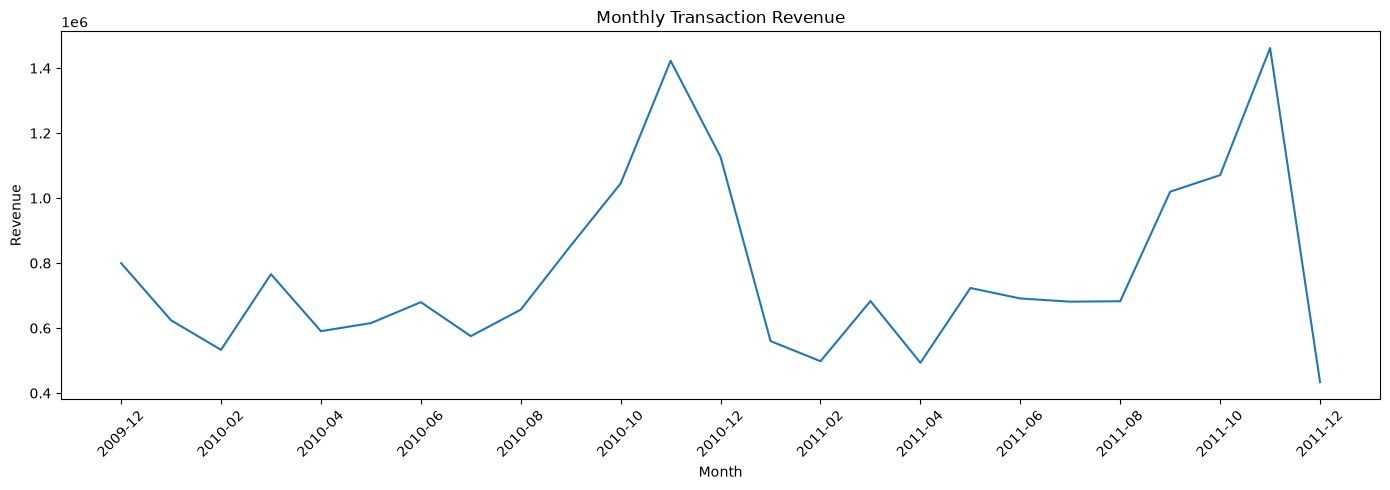

In [30]:
# Monthly revenue trend

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_activity["Month"],
    monthly_activity["revenue"]
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Transaction Revenue")

plt.xticks(
    range(
        0,
        len(monthly_activity),
        max(1, len(monthly_activity) // 12)
    ),
    rotation=45
)

plt.tight_layout()
plt.show()

### 9.3 Customer Activity Span

Customer activity duration is examined to understand how long customers remain
observable within the dataset.

This provides an important foundation for later CLV feature engineering,
including customer tenure, recency, and historical purchasing behaviour.

In [31]:
# Customer-level activity span

customer_activity = (
    df.dropna(subset=["Customer ID", "InvoiceDate"])
    .groupby("Customer ID")
    .agg(
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max"),
        transaction_count=("InvoiceDate", "size"),
        total_revenue=("TransactionRevenue", "sum"),
    )
    .reset_index()
)

customer_activity["activity_days"] = (
    customer_activity["last_purchase"]
    - customer_activity["first_purchase"]
).dt.days

customer_activity.head()

,Customer ID,first_purchase,last_purchase,transaction_count,total_revenue,activity_days
0,"12,346.00",2009-12-14 08:34:00,2011-01-18 10:17:00,48,-64.68,400
1,"12,347.00",2010-10-31 14:20:00,2011-12-07 15:52:00,253,"5,633.32",402
2,"12,348.00",2010-09-27 14:59:00,2011-09-25 13:13:00,51,"2,019.40",362
3,"12,349.00",2009-12-04 12:49:00,2011-11-21 09:51:00,180,"4,404.54",716
4,"12,350.00",2011-02-02 16:01:00,2011-02-02 16:01:00,17,334.40,0


In [32]:
# Customer activity-span statistics

customer_activity[
    [
        "activity_days",
        "transaction_count",
        "total_revenue",
    ]
].describe()

,activity_days,transaction_count,total_revenue
count,"5,942.00","5,942.00","5,942.00"
mean,275.40,138.74,"2,801.80"
std,259.69,359.69,"13,973.92"
min,0.00,1.00,"-25,111.09"
25%,0.00,21.00,325.10
50%,225.00,53.00,843.97
75%,517.00,144.00,"2,182.01"
max,738.00,"13,097.00","598,215.22"


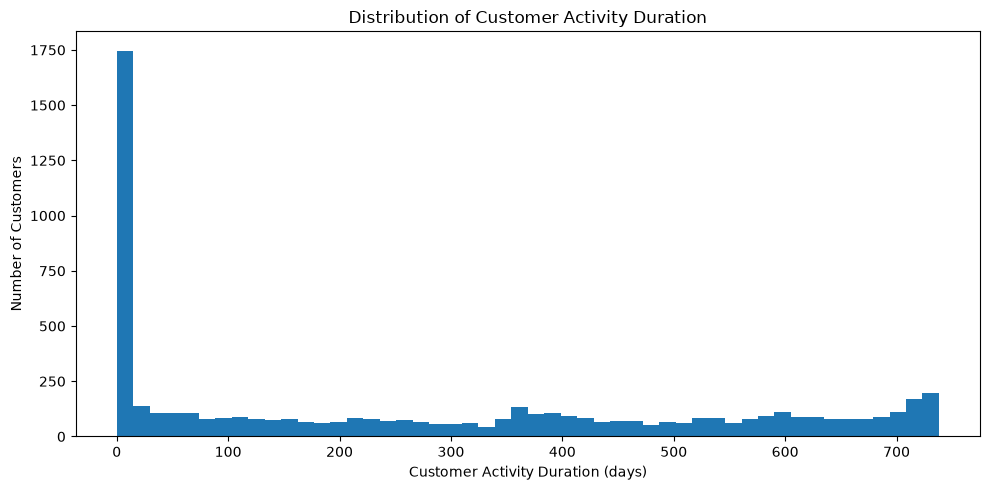

In [33]:
# Distribution of customer activity duration

plt.figure(figsize=(10, 5))

plt.hist(
    customer_activity["activity_days"],
    bins=50
)

plt.xlabel("Customer Activity Duration (days)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Activity Duration")

plt.tight_layout()
plt.show()

## 10. Temporal Validation Summary

The temporal analysis establishes the time coverage and purchasing behaviour of
the dataset before defining the CLV prediction framework.

The following decisions remain intentionally open:

- Observation window
- Prediction horizon
- Customer inclusion criteria
- Treatment of cancelled transactions
- Final CLV target definition

These decisions will be made after the temporal and customer-level behaviour
has been fully examined.

In [34]:
print("Temporal Validation Summary")
print("=" * 40)

print(f"Dataset start date       : {df['InvoiceDate'].min()}")
print(f"Dataset end date         : {df['InvoiceDate'].max()}")
print(f"Unique transaction days  : {df['InvoiceDate'].dt.normalize().nunique():,}")
print(f"Unique customers         : {df['Customer ID'].nunique():,}")
print(f"Unique invoices          : {df[invoice_column].nunique():,}")

Temporal Validation Summary
Dataset start date       : 2009-12-01 07:45:00
Dataset end date         : 2011-12-09 12:50:00
Unique transaction days  : 604
Unique customers         : 5,942
Unique invoices          : 53,628


## 11. Customer-Level Exploratory Data Analysis

This section examines customer purchasing behaviour using the Online Retail II
transaction dataset.

The analysis focuses on:

- Customer identification coverage
- Purchase frequency
- Invoice-level monetary value
- Customer-level spending distributions
- Customer activity patterns
- Differences between raw transaction records and provisional completed purchases

Records with missing Customer ID values cannot be assigned reliably to
individual customers and will be excluded from customer-level aggregations
only, without being removed from the original DataFrame.

For exploratory purchase analysis, cancelled invoices and non-positive quantity
or price values will be excluded from a separate analytical DataFrame.

These provisional filters are analytical choices, not final data-cleaning
decisions or the final CLV target definition.

In [35]:
# Prepare customer-level analytical data without modifying the raw dataset

customer_records = df.dropna(
    subset=["Customer ID", "InvoiceDate"]
).copy()

# Identify completed-purchase candidates for exploratory analysis.
# This is a provisional analytical subset, not the final cleaned dataset.

purchase_mask = (
    ~customer_records[invoice_column]
    .astype("string")
    .str.startswith("C", na=False)
) & (
    customer_records["Quantity"] > 0
) & (
    customer_records[price_column] > 0
)

purchase_records = customer_records.loc[purchase_mask].copy()

print(f"Raw transaction records       : {len(df):,}")
print(f"Records with identified customer: {len(customer_records):,}")
print(f"Provisional purchase records   : {len(purchase_records):,}")
print(
    "Unique identified customers    : "
    f"{purchase_records['Customer ID'].nunique():,}"
)
print(
    "Unique provisional purchase invoices: "
    f"{purchase_records[invoice_column].nunique():,}"
)

Raw transaction records       : 1,067,371
Records with identified customer: 824,364
Provisional purchase records   : 805,549
Unique identified customers    : 5,878
Unique provisional purchase invoices: 36,969


In [36]:
# Build a customer-level purchase-frequency summary

customer_frequency = (
    purchase_records
    .groupby("Customer ID")
    .agg(
        invoice_count=(invoice_column, "nunique"),
        product_line_count=(invoice_column, "size"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max"),
    )
    .reset_index()
)

customer_frequency["activity_days"] = (
    customer_frequency["last_purchase"]
    - customer_frequency["first_purchase"]
).dt.days

customer_frequency.head()

,Customer ID,invoice_count,product_line_count,first_purchase,last_purchase,activity_days
0,"12,346.00",12,34,2009-12-14 08:34:00,2011-01-18 10:01:00,400
1,"12,347.00",8,253,2010-10-31 14:20:00,2011-12-07 15:52:00,402
2,"12,348.00",5,51,2010-09-27 14:59:00,2011-09-25 13:13:00,362
3,"12,349.00",4,175,2010-04-29 13:20:00,2011-11-21 09:51:00,570
4,"12,350.00",1,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0


In [37]:
# Calculate provisional invoice-level monetary values first

invoice_values = (
    purchase_records
    .assign(
        line_revenue=(
            purchase_records["Quantity"]
            * purchase_records[price_column]
        )
    )
    .groupby(
        ["Customer ID", invoice_column],
        as_index=False
    )
    .agg(
        invoice_revenue=("line_revenue", "sum"),
        invoice_date=("InvoiceDate", "min"),
    )
)

# Aggregate invoice values to the customer level

customer_monetary = (
    invoice_values
    .groupby("Customer ID")
    .agg(
        total_purchase_value=("invoice_revenue", "sum"),
        average_invoice_value=("invoice_revenue", "mean"),
        median_invoice_value=("invoice_revenue", "median"),
        invoice_count=(invoice_column, "nunique"),
    )
    .reset_index()
)

customer_monetary.head()

,Customer ID,total_purchase_value,average_invoice_value,median_invoice_value,invoice_count
0,"12,346.00","77,556.46","6,463.04",22.50,12
1,"12,347.00","5,633.32",704.16,598.22,8
2,"12,348.00","2,019.40",403.88,310.00,5
3,"12,349.00","4,428.69","1,107.17","1,235.57",4
4,"12,350.00",334.40,334.40,334.40,1


In [38]:
# Descriptive statistics for customer-level monetary value

customer_monetary[
    [
        "total_purchase_value",
        "average_invoice_value",
        "median_invoice_value",
        "invoice_count",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
total_purchase_value,"5,878.00","3,018.62","14,737.73",2.95,348.76,898.91,"2,307.09","608,821.65"
average_invoice_value,"5,878.00",391.73,"1,215.07",2.95,181.65,285.07,420.57,"84,236.25"
median_invoice_value,"5,878.00",368.19,"1,194.53",2.95,169.47,278.01,396.42,"84,236.25"
invoice_count,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,398.00


In [39]:
# Inspect customers with the highest provisional purchase values

customer_monetary.sort_values(
    "total_purchase_value",
    ascending=False
).head(20)

,Customer ID,total_purchase_value,average_invoice_value,median_invoice_value,invoice_count
5692,"18,102.00","608,821.65","4,198.77","2,350.98",145
2277,"14,646.00","528,602.52","3,500.68","1,407.86",151
1789,"14,156.00","313,946.37","2,012.48",791.14,156
2538,"14,911.00","295,972.63",743.65,637.62,398
5050,"17,450.00","246,973.09","4,842.61","2,907.20",51
1331,"13,694.00","196,482.81","1,374.01",978.21,143
5109,"17,511.00","175,603.55","2,926.73","3,177.04",60
4061,"16,446.00","168,472.50","84,236.25","84,236.25",2
4295,"16,684.00","147,142.77","2,675.32","1,421.40",55
68,"12,415.00","144,458.37","5,159.23",708.62,28


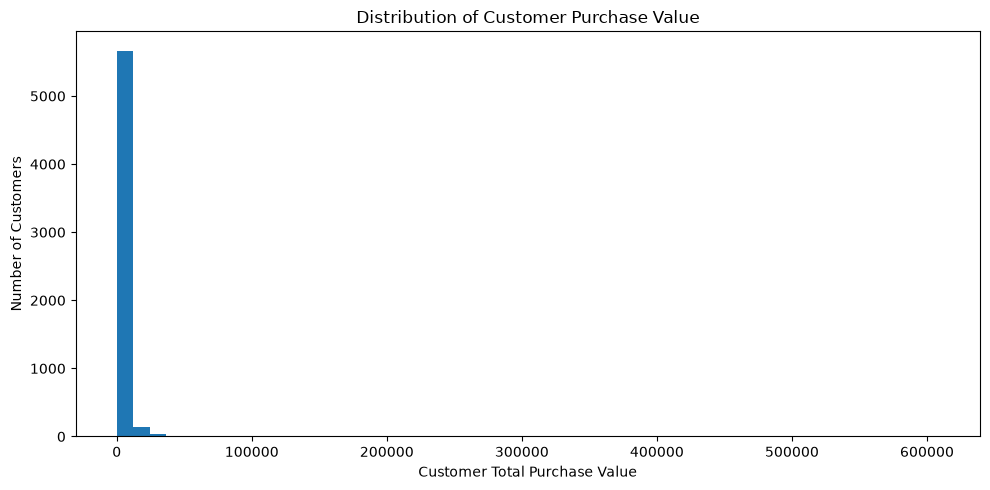

In [40]:
# Customer spending distribution

plt.figure(figsize=(10, 5))

plt.hist(
    customer_monetary["total_purchase_value"],
    bins=50
)

plt.xlabel("Customer Total Purchase Value")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Purchase Value")

plt.tight_layout()
plt.show()

## 12. Customer Purchasing Behaviour Analysis

This section investigates the distribution of customer purchase frequency,
customer activity duration, and monetary value.

The analysis examines:

- Distribution of invoices per customer
- Distribution of customer activity duration
- Relationship between purchase frequency and monetary value
- Customer-level purchasing concentration

These results will help assess the characteristics of the customer population
before defining the CLV prediction target.

No final CLV target, observation window, or prediction horizon is defined here.

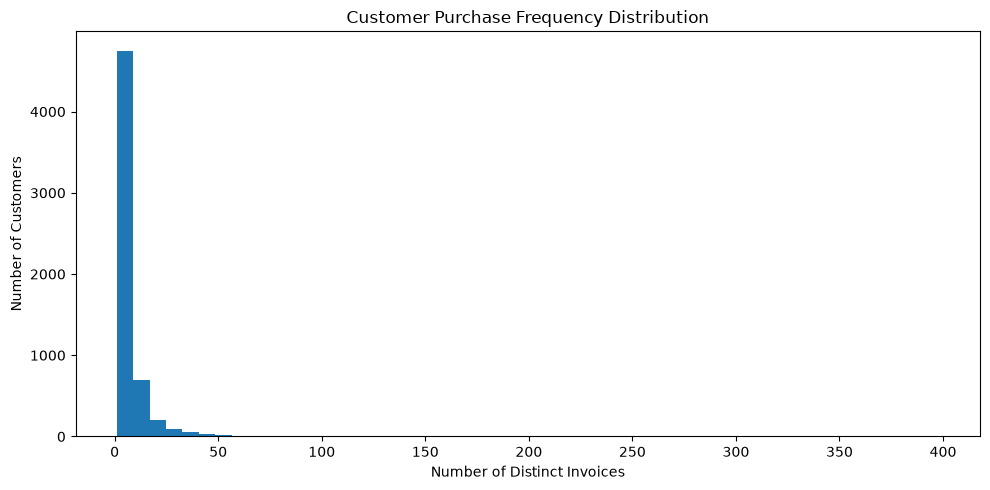

In [41]:
# Distribution of distinct purchase invoices per customer

plt.figure(figsize=(10, 5))

plt.hist(
    customer_frequency["invoice_count"],
    bins=50
)

plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.title("Customer Purchase Frequency Distribution")

plt.tight_layout()
plt.show()

In [42]:
# Descriptive statistics for customer purchase frequency

customer_frequency[
    [
        "invoice_count",
        "product_line_count",
        "activity_days",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
invoice_count,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,398.00
product_line_count,"5,878.00",137.04,353.82,1.00,21.00,53.00,142.00,"12,890.00"
activity_days,"5,878.00",273.02,258.81,0.00,0.00,220.50,511.00,738.00


In [43]:
# Combine frequency and monetary metrics

customer_behavior = customer_frequency.merge(
    customer_monetary[
        [
            "Customer ID",
            "total_purchase_value",
            "average_invoice_value",
            "median_invoice_value",
        ]
    ],
    on="Customer ID",
    how="inner",
    validate="one_to_one",
)

customer_behavior.head()

,Customer ID,invoice_count,product_line_count,first_purchase,last_purchase,activity_days,total_purchase_value,average_invoice_value,median_invoice_value
0,"12,346.00",12,34,2009-12-14 08:34:00,2011-01-18 10:01:00,400,"77,556.46","6,463.04",22.50
1,"12,347.00",8,253,2010-10-31 14:20:00,2011-12-07 15:52:00,402,"5,633.32",704.16,598.22
2,"12,348.00",5,51,2010-09-27 14:59:00,2011-09-25 13:13:00,362,"2,019.40",403.88,310.00
3,"12,349.00",4,175,2010-04-29 13:20:00,2011-11-21 09:51:00,570,"4,428.69","1,107.17","1,235.57"
4,"12,350.00",1,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.40,334.40,334.40


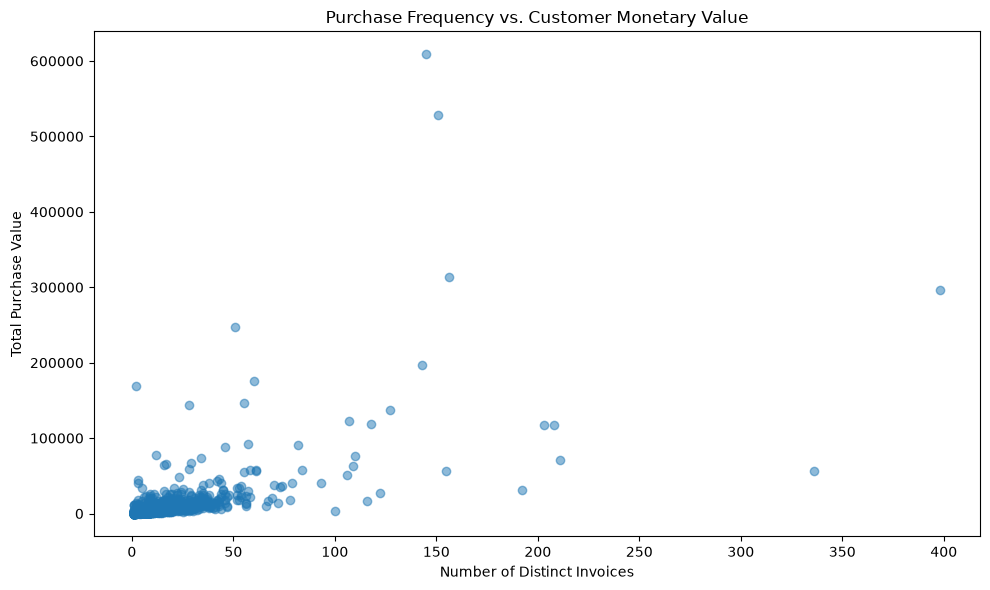

In [44]:
# Examine the relationship between purchase frequency and total value

plt.figure(figsize=(10, 6))

plt.scatter(
    customer_behavior["invoice_count"],
    customer_behavior["total_purchase_value"],
    alpha=0.5,
)

plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Total Purchase Value")
plt.title("Purchase Frequency vs. Customer Monetary Value")

plt.tight_layout()
plt.show()

In [45]:
# Correlation between selected customer-level metrics

customer_behavior[
    [
        "invoice_count",
        "product_line_count",
        "activity_days",
        "total_purchase_value",
        "average_invoice_value",
        "median_invoice_value",
    ]
].corr()

,invoice_count,product_line_count,activity_days,total_purchase_value,average_invoice_value,median_invoice_value
invoice_count,1.00,0.81,0.44,0.63,0.04,0.01
product_line_count,0.81,1.00,0.35,0.47,0.04,0.03
activity_days,0.44,0.35,1.00,0.21,0.02,0.00
total_purchase_value,0.63,0.47,0.21,1.00,0.27,0.21
average_invoice_value,0.04,0.04,0.02,0.27,1.00,0.98
median_invoice_value,0.01,0.03,0.00,0.21,0.98,1.00


In [46]:
# Measure the concentration of observed purchase value among customers

customer_values = customer_behavior[
    "total_purchase_value"
].sort_values(ascending=False)

total_value = customer_values.sum()

if total_value > 0:
    top_10_percent_count = max(
        1,
        int(np.ceil(len(customer_values) * 0.10))
    )

    top_10_percent_value = customer_values.head(
        top_10_percent_count
    ).sum()

    top_10_percent_share = (
        top_10_percent_value / total_value
    ) * 100

    print(
        f"Customers analysed: {len(customer_values):,}"
    )
    print(
        "Share of observed purchase value generated by "
        f"the top 10% of customers: {top_10_percent_share:.2f}%"
    )
else:
    print(
        "Customer monetary values do not have a positive total; "
        "review the analytical data before interpreting concentration."
    )

Customers analysed: 5,878
Share of observed purchase value generated by the top 10% of customers: 63.93%


## 13. EDA Findings and Handoff to Feature Engineering

### Findings from the observed data

- The workbook contains **1,067,371 transaction-line records**, spanning **1 December 2009 to 9 December 2011** (739 calendar days, with transactions on 604 distinct dates).
- **243,007 records** lack a customer identifier, so they cannot be assigned to a customer reliably. Customer-level analysis must use identified customers while preserving the raw dataset.
- **34,335 exact duplicate rows (3.22%)** were detected. They have not been deleted; duplicate-looking rows require business-context review before any removal.
- The raw data includes **22,950 negative-quantity records**, **6,202 zero-price records**, and **5 negative-price records**. Cancellation and non-positive values need an explicit, documented treatment in the modelling dataset.
- The provisional purchase subset contains **805,549 rows, 5,878 customers, and 36,969 distinct invoices** after excluding missing customer/date rows, cancellation invoices, and non-positive quantity/price values.
- Customer purchase frequency is strongly right-skewed: median **3 invoices** and mean **6.29 invoices** per customer; the maximum is **398 invoices**.
- Provisional customer purchase value is also highly skewed: median **898.91** and mean **3,018.62**. The top 10% of customers account for **63.93%** of the total provisional purchase value.
- Purchase frequency and total purchase value have a positive correlation (**0.63**) in this exploratory subset. Average and median invoice values are highly correlated (**0.98**), so they may be redundant features.

### Important caveats

- `TransactionRevenue = Quantity × Price` is an exploratory measure, not yet the final CLV target.
- Extreme transaction and customer monetary values are present. For example, the raw transaction inspection found a line value of **168,469.60**, and the provisional customer table contains very large totals. Investigate these records and their business meaning in feature engineering; do not remove them solely because they are large.
- The dataset starts and ends partway through calendar months. This partial coverage, customer acquisition timing, and the need for a future target period must be considered when selecting the observation window and prediction horizon.
- `product_line_count` counts transaction rows, not distinct invoices. Use `invoice_count` for distinct purchase invoices.
- The customer-level summaries use provisional filters. They are exploratory and should not be treated as the final cleaned modelling dataset.

### Handoff decision

Notebook 01 establishes the dataset quality, temporal coverage, and customer purchasing patterns. The next notebook will define a **future-value prediction target** using a time-based observation window and prediction horizon, create customer-level features, investigate extreme values, and verify that no future information leaks into the features.

**No final CLV target, observation window, prediction horizon, cleaning rule for extreme values, or final regression algorithm is locked in this notebook.**
